KẾT QUẢ THỬ NGHIỆM
 Mức nhiễu  Độ chính xác
      0.00      0.783333
      0.05      0.812500
      0.10      0.816667
      0.20      0.733333
      0.30      0.708333


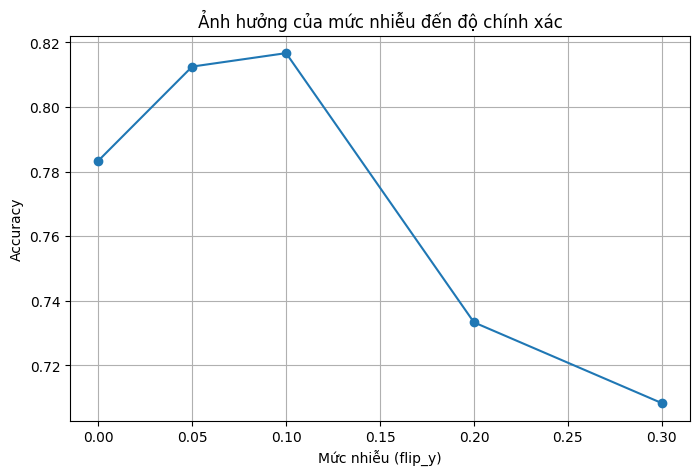

In [1]:


import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


muc_nhieu = [0.0, 0.05, 0.10, 0.20, 0.30]

ket_qua = []

for noise in muc_nhieu:

    X, y = make_classification(
        n_samples=1200,
        n_features=10,
        n_informative=6,
        n_redundant=2,
        n_classes=2,
        flip_y=noise,
        class_sep=1.0,
        random_state=42
    )


    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )


    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)


    y_pred = model.predict(X_test)


    accuracy = accuracy_score(y_test, y_pred)

    ket_qua.append({
        "Mức nhiễu": noise,
        "Độ chính xác": accuracy
    })


df_ket_qua = pd.DataFrame(ket_qua)

print("KẾT QUẢ THỬ NGHIỆM")
print(df_ket_qua.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(
    df_ket_qua["Mức nhiễu"],
    df_ket_qua["Độ chính xác"],
    marker="o"
)

plt.title("Ảnh hưởng của mức nhiễu đến độ chính xác")
plt.xlabel("Mức nhiễu (flip_y)")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

SO SÁNH KẾT QUẢ THEO NGƯỠNG
 Ngưỡng  Accuracy  Precision  Recall  F1-score
    0.5    0.8067     0.8013  0.8121    0.8067
    0.6    0.8067     0.8527  0.7383    0.7914
    0.7    0.7767     0.8868  0.6309    0.7373


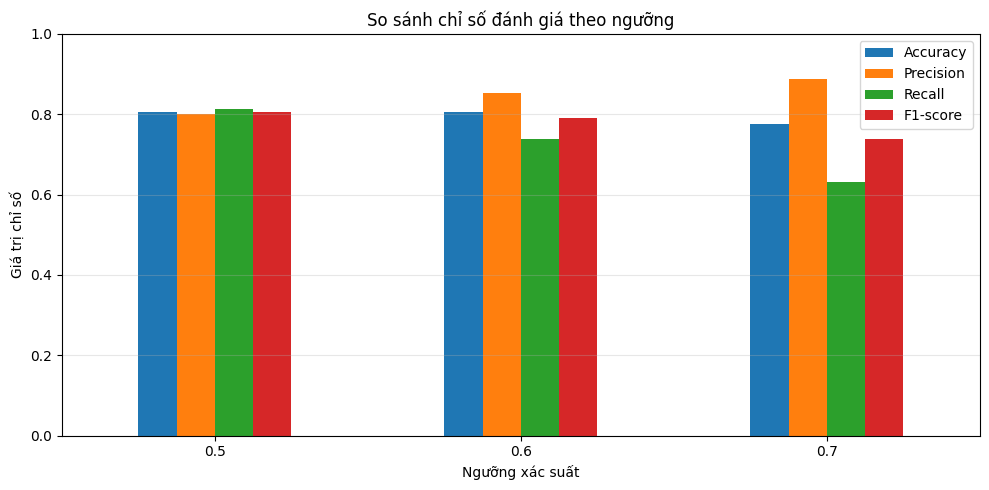

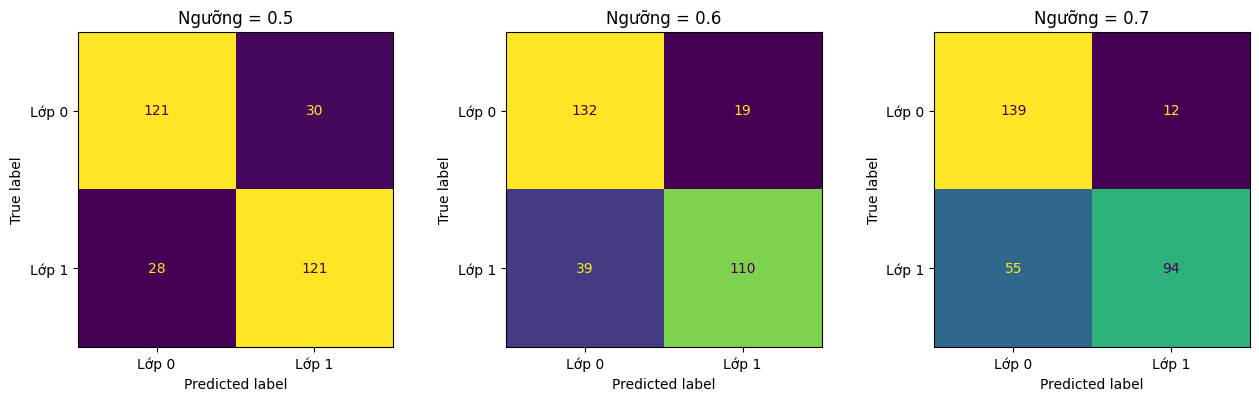

In [2]:


import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


X, y = make_classification(
    n_samples=1500,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    n_classes=2,
    flip_y=0.08,
    class_sep=1.0,
    random_state=42
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)


y_prob = model.predict_proba(X_test)[:, 1]


nguong_list = [0.5, 0.6, 0.7]
ket_qua = {}
bang_ket_qua = []

for nguong in nguong_list:

    y_pred = (y_prob >= nguong).astype(int)

    ket_qua[nguong] = y_pred

    bang_ket_qua.append({
        "Ngưỡng": nguong,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })


df_nguong = pd.DataFrame(bang_ket_qua)

print("SO SÁNH KẾT QUẢ THEO NGƯỠNG")
print(df_nguong.round(4).to_string(index=False))


df_plot = df_nguong.set_index("Ngưỡng")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
]

df_plot.plot(kind="bar", figsize=(10, 5))
plt.title("So sánh chỉ số đánh giá theo ngưỡng")
plt.xlabel("Ngưỡng xác suất")
plt.ylabel("Giá trị chỉ số")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, nguong in zip(axes, nguong_list):
    cm = confusion_matrix(y_test, ket_qua[nguong])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Lớp 0", "Lớp 1"]
    )

    disp.plot(ax=ax, colorbar=False)
    ax.set_title(f"Ngưỡng = {nguong}")

plt.tight_layout()
plt.show()

Đã tải dữ liệu Boston Housing từ OpenML.

KÍCH THƯỚC DỮ LIỆU
Số dòng: 506
Số thuộc tính: 13

5 DÒNG DỮ LIỆU ĐẦU TIÊN
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9.14  21.6  
2     17.8  392.83   4.03  34.7  
3     18.7  394.63   2.94  33.4  
4     18.7  396.90   5.33  36.2  

KÍCH THƯỚC CÁC TẬP DỮ LIỆU
Tập huấn luyện: 404 mẫu
Tập kiểm tra: 102 mẫu

ĐÃ HUẤN LUYỆN XONG MÔ HÌNH LINEAR REGRESSION

KẾT QUẢ DỰ ĐOÁN 10 MẪU ĐẦU TIÊN
 Giá thực tế  Giá dự đoán
        23.6       28.997
        32.4       36.026
        1

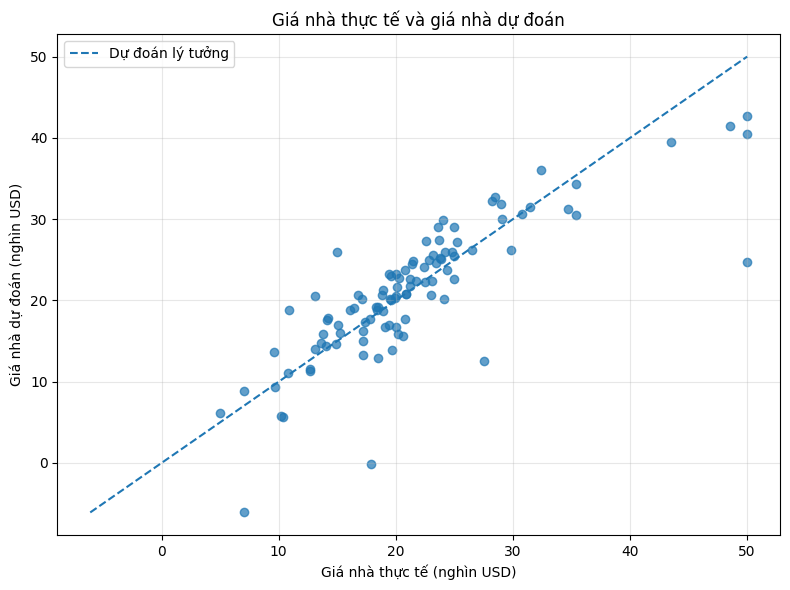

In [3]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score



try:

    boston = fetch_openml(data_id=531, as_frame=False)

    X = pd.DataFrame(
        boston.data,
        columns=boston.feature_names
    )

    y = pd.Series(
        pd.to_numeric(boston.target, errors="coerce"),
        name="MEDV"
    )


    du_lieu = X.copy()
    du_lieu["MEDV"] = y
    du_lieu = du_lieu.dropna()

    X = du_lieu.drop(columns=["MEDV"])
    y = du_lieu["MEDV"]

    print("Đã tải dữ liệu Boston Housing từ OpenML.")

except Exception as e:

    import urllib.request

    print("Không tải được từ OpenML, đang thử nguồn dữ liệu gốc...")

    data_url = "https://lib.stat.cmu.edu/datasets/boston"

    try:

        with urllib.request.urlopen(data_url, timeout=30) as response:
            raw_df = pd.read_csv(
                response,
                sep=r"\s+",
                skiprows=22,
                header=None
            )
    except Exception:

        data_url = "http://lib.stat.cmu.edu/datasets/boston"

        with urllib.request.urlopen(data_url, timeout=30) as response:
            raw_df = pd.read_csv(
                response,
                sep=r"\s+",
                skiprows=22,
                header=None
            )


    data = np.hstack([
        raw_df.values[::2, :],
        raw_df.values[1::2, :2]
    ])

    target = raw_df.values[1::2, 2]

    feature_names = [
        "CRIM", "ZN", "INDUS", "CHAS", "NOX",
        "RM", "AGE", "DIS", "RAD", "TAX",
        "PTRATIO", "B", "LSTAT"
    ]

    X = pd.DataFrame(data, columns=feature_names)
    y = pd.Series(target, name="MEDV")

    print("Đã tải dữ liệu Boston Housing từ nguồn dữ liệu gốc.")


X = X.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(y, errors="coerce")


du_lieu = X.copy()
du_lieu["MEDV"] = y
du_lieu = du_lieu.dropna()

X = du_lieu.drop(columns=["MEDV"])
y = du_lieu["MEDV"]

print("\nKÍCH THƯỚC DỮ LIỆU")
print("Số dòng:", X.shape[0])
print("Số thuộc tính:", X.shape[1])

print("\n5 DÒNG DỮ LIỆU ĐẦU TIÊN")
print(du_lieu.head())



X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nKÍCH THƯỚC CÁC TẬP DỮ LIỆU")
print("Tập huấn luyện:", X_train.shape[0], "mẫu")
print("Tập kiểm tra:", X_test.shape[0], "mẫu")


model = LinearRegression()

model.fit(X_train, y_train)

print("\nĐÃ HUẤN LUYỆN XONG MÔ HÌNH LINEAR REGRESSION")



y_pred = model.predict(X_test)


bang_du_doan = pd.DataFrame({
    "Giá thực tế": y_test.values,
    "Giá dự đoán": y_pred
})

print("\nKẾT QUẢ DỰ ĐOÁN 10 MẪU ĐẦU TIÊN")
print(bang_du_doan.head(10).round(3).to_string(index=False))



mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nCÁC CHỈ SỐ ĐÁNH GIÁ MÔ HÌNH")
print(f"MSE (Mean Squared Error): {mse:.4f}")
print(f"R2 score: {r2:.4f}")



plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)


gia_min = min(y_test.min(), y_pred.min())
gia_max = max(y_test.max(), y_pred.max())

plt.plot(
    [gia_min, gia_max],
    [gia_min, gia_max],
    linestyle="--",
    label="Dự đoán lý tưởng"
)

plt.title("Giá nhà thực tế và giá nhà dự đoán")
plt.xlabel("Giá nhà thực tế (nghìn USD)")
plt.ylabel("Giá nhà dự đoán (nghìn USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()